## CMF-BO-GP 4.1

### Function 4 - Dynamic

The model has four hyperparameters to tune, and its output reflects the differnece from the expensive baseline. Because the system is dynamic and full of local optima, it requires careful tuning and robust validation to find reliable, near-optimal solutions

### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - for pairs of features
#### 4. Core Model - v1 - UCB / EI models - with length scales and bounds
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [ ]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================


import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.stats import norm
from scipy.interpolate import griddata

In [ ]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# Your 4D spatial coordinate data (10 positions)
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC4/initial_inputs.npy')

# Your ouput values
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC4/initial_outputs.npy')

print(f"Base Maximia: ",output.max())

extra_inputs = [[0.413038, 0.408189, 0.347264, 0.431326],[0.413038, 0.408189, 0.347264, 0.431326],
                [0.435949, 0.443948, 0.243355, 0.439113],[0.344064, 0.436389, 0.466159, 0.458097],
                [0.473737, 0.329747, 0.407231, 0.480575],[0.463369, 0.565191, 0.411343, 0.429494],
               	[0.484691, 0.419585, 0.363640, 0.389904],[0.414488, 0.445090, 0.366821, 0.528614],
                [0.429795, 0.353960, 0.305369, 0.441566],[0.350000, 0.399406, 0.351519, 0.398510],
                [0.350000, 0.391487, 0.298188, 0.350000],[0.383860, 0.394366, 0.376949, 0.414908]]
extra_output = [0.5481902259003815,0.5481902259003815,-1.847789200471531,
                -0.9368462707140419,-2.1240106008010033,-3.291222601614592,
               -1.0738604820061286,-1.6546686947288474,-0.5874086492983355,
                0.5123117950112541,-0.8076911864710783,0.2718489456680122]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)

print(f"Current Maxima: ",output.max())



# 2. Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_W','Input_X', 'Input_Y', 'Input_Z'])
df['Output_Target'] = output

# 3. Compute the correlation matrix
# Change method to 'spearman' if relationships are non-linear curves
corr_matrix = df.corr(method='pearson')

# 4. Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_W','Input_X', 'Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")

# Fit a quick non-linear model that checks all 4 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_W','Input_X', 'Input_Y', 'Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

Base Maximia:  -4.025542281908162
Current Maxima:  0.5481902259003815
Correlation with Output:
Input_W   -0.510551
Input_X   -0.385117
Input_Y   -0.222489
Input_Z   -0.391171
Name: Output_Target, dtype: float64
Input_W Mutual Information Score: 0.5918
Input_X Mutual Information Score: 0.6365
Input_Y Mutual Information Score: 0.3237
Input_Z Mutual Information Score: 0.5368
Input_W Total Importance (with interactions): 0.3556
Input_X Total Importance (with interactions): 0.3038
Input_Y Total Importance (with interactions): 0.1178
Input_Z Total Importance (with interactions): 0.2229


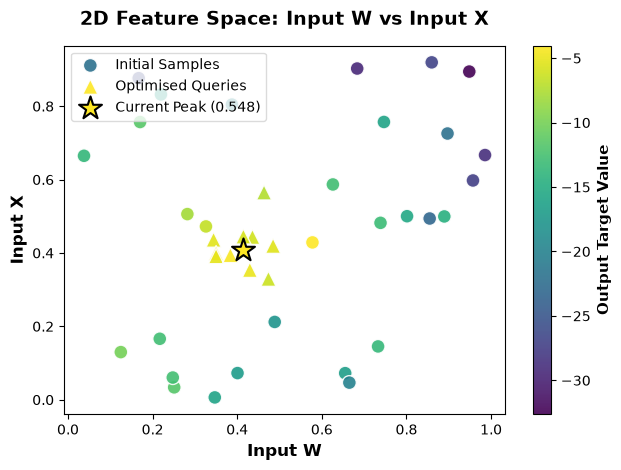

In [4]:
# ===================================
# 3.1 Visualise the data set W and X
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_W']
max_z = df.loc[max_row_index, 'Input_X']
max_val = df.loc[max_row_index, 'Output_Target']



# Create scatter plot with the first 30 smaples
scatter1 = plt.scatter(
    data=df.iloc[:30], 
    x='Input_W', 
    y='Input_X', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[30:len(output)], 
    x='Input_W', 
    y='Input_X', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next 9 points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input W', fontsize=12, fontweight='bold')
plt.ylabel('Input X', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input W vs Input X', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

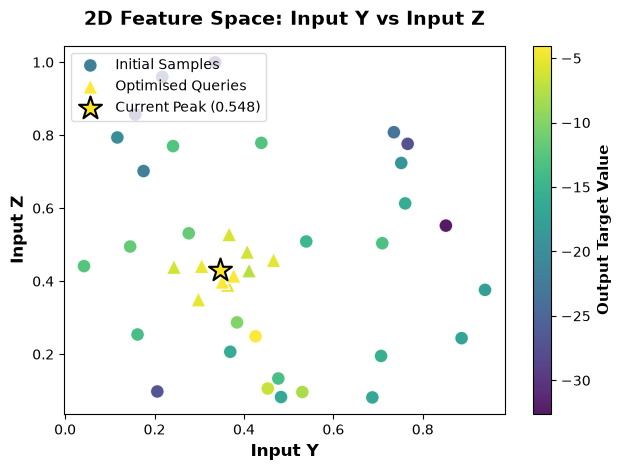

In [5]:

# ===================================
# 3.2 Visualise the data set Y and Z
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_Y']
max_z = df.loc[max_row_index, 'Input_Z']
max_val = df.loc[max_row_index, 'Output_Target']



# Create scatter plot with the first 30 smaples
scatter1 = plt.scatter(
    data=df.iloc[:30], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[30:len(output)], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next 9 points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input Y', fontsize=12, fontweight='bold')
plt.ylabel('Input Z', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input Y vs Input Z', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

In [6]:
# ===========================================
# 4 (v1) GP Model - with UCB/EI 
# ===========================================

import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Train a predictive model on your 20 existing samples
predictor = RandomForestRegressor(n_estimators=100, random_state=42)
predictor.fit(inputs, output)

def objective_4d(X):
    """
    Surrogate function for 4D optimization.
    X: A 2D numpy array of shape (n_samples, 4) sent by the optimizer.
    """
    # Force input to be 2D array matrix for sklearn compatibility
    X = np.atleast_2d(X)
    
    # Predict the output value using the trained model
    predictions = predictor.predict(X)
    
    # Return as a flat 1D array as expected by your code (.ravel())
    print(f"Prediction {predictions}")
    return predictions.ravel()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

def upper_confidence_bound(mu, sigma, kappa=0.1):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma


def expected_improvement(mu, sigma, y_best, xi=0.05):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [8]:
def bayesian_optimization_nd(objective_func, n_dims, n_iterations=1, 
                            n_initial=5, acquisition='ei'):
    """
    Bayesian Optimization for n-dimensional functions.
    Assumes bounds [0, 1] for all dimensions.
    """
    bounds = [(0, 1) for _ in range(n_dims)]
    
    # Initialize
    X_samples = inputs
    y_samples = output
    
    
    best_values = [y_samples.max()]
    
    print(f"Starting {n_dims}D optimization with {n_initial} initial samples...")
    print(f"Initial best: {y_samples.max():.4f}\n")
  
    
    for iteration in range(n_iterations):
        # Fit GP
        kernel = ConstantKernel(1.0) * Matern(length_scale=0.3,nu=2.5)
        gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,normalize_y=True,
                                     n_restarts_optimizer=5)
        gp.fit(X_samples, y_samples)

        # Optimize acquisition function
        def acq_objective(X):
            X = X.reshape(1, -1)
            mu, sigma = gp.predict(X, return_std=True)
            
            if acquisition == 'ei':
                acq_val = expected_improvement(mu, sigma, y_samples.max())
            else:
                acq_val = upper_confidence_bound(mu, sigma, kappa=1)
           
            return -acq_val
        
        # Multi-start optimization
        best_acq = np.inf
        X_next = None
        # Build dynamic, localized acquisition optimization bounds
        #
        localized_bounds = [
            (0.30, 0.5),  # Input_W restricted search
            (0.30, 0.5),  # Input_X restricted search
            (0.2, 0.45),  # Input_Y restricted search
            (0.35, 0.55),  # Input_Z restricted search
        ]

        
        for _ in range(50):  # More starts for higher dimensions
            # Sample initial multi-start points respecting the localized constraints
            x0 = np.array(
                [
                    np.random.uniform(localized_bounds[0][0], bounds[0][1]),
                    np.random.uniform(localized_bounds[1][0], bounds[1][1]),
                    np.random.uniform(localized_bounds[2][0], bounds[2][1]),
                    np.random.uniform(localized_bounds[3][0], bounds[3][1])
                ]
            )
            result = minimize(acq_objective, x0, bounds=localized_bounds, method='L-BFGS-B',options={"ftol": 1e-9},) 
      
            if result.fun < best_acq:
                best_acq = result.fun
                X_next = result.x
                print(f"Optimized Next Point Found! Predicted Acquisition Score: {-best_acq:.6f}")
                print(f"Coordinates to test next: {X_next}")

       
        # Evaluate
        y_next = objective_func(X_next.reshape(1, -1)).ravel()
        
        # Update
        X_samples = np.vstack([X_samples, X_next])
        y_samples = np.append(y_samples, y_next)
        best_values.append(y_samples.max())
        
        if (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Best f(x)={y_samples.max():.4f}")
    
    return X_samples, y_samples, best_values



# Run 4D optimization
X_samples_4d, y_samples_4d, best_values_4d = bayesian_optimization_nd(
    objective_4d, 
    n_dims=4,
    n_iterations=5,
    acquisition=''
)

Starting 4D optimization with 5 initial samples...
Initial best: 0.5482

Optimized Next Point Found! Predicted Acquisition Score: 1.285771
Coordinates to test next: [0.3258986  0.44796355 0.33817583 0.43201788]
Optimized Next Point Found! Predicted Acquisition Score: 1.285771
Coordinates to test next: [0.32589776 0.44796401 0.33817596 0.43201781]
Optimized Next Point Found! Predicted Acquisition Score: 1.285771
Coordinates to test next: [0.32589816 0.44796355 0.33817569 0.43201792]
Optimized Next Point Found! Predicted Acquisition Score: 1.285771
Coordinates to test next: [0.32589778 0.44796358 0.33817582 0.43201798]
Optimized Next Point Found! Predicted Acquisition Score: 1.285771
Coordinates to test next: [0.32589821 0.44796375 0.33817586 0.43201801]
Optimized Next Point Found! Predicted Acquisition Score: 1.285771
Coordinates to test next: [0.32589797 0.44796359 0.33817577 0.43201814]
Prediction [-3.09432746]
Optimized Next Point Found! Predicted Acquisition Score: 0.701229
Coordina

In [9]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================

## import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize

# 1. Load the 5D dataset (Features: W, X, Y, Z)
X_train = inputs
y_train = output

# 2. Configure a Matern GP Surrogate Model
# Matern nu=1.5 allows for the distinct "cliffs"
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(4), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)

# Fit model to historical space
gp.fit(X_train, y_train)

# 3. Formulate Optimization Target (Negative prediction for minimization algorithm)
def objective(x):
    # Predict returns shape (1, 5), flatten to extract scalar
    return -float(gp.predict(x.reshape(1, -1))[0])

# 4. Enforce Bounding Box System limits [0.0, 1.0]
bounds = [
    (0.30, 0.5),  # W
    (0.30, 0.5),  # X
    (0.30, 0.5),  # Y
    (0.30, 0.5)   # Z
]

# Use your historical peak coordinate as the optimization warm-start point
x_start = np.array([0.413038, 0.408189, 0.347264, 0.431326])

# 5. Execute L-BFGS-B Optimization Local Search
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)

# 6. Display Predicted Coordinates
print("--- GAUSSIAN PROCESS TARGET PREDICTION ---")
print(f"Predicted Max Output: {abs(result.fun):.4f}")
print("Optimal Coordinates:")
for name, val in zip(['W', 'X', 'Y', 'Z'], result.x):
    print(f"  Input_{name}: {val:.6f}")


--- GAUSSIAN PROCESS TARGET PREDICTION ---
Predicted Max Output: 0.7978
Optimal Coordinates:
  Input_W: 0.365114
  Input_X: 0.415710
  Input_Y: 0.340933
  Input_Z: 0.428682
